# Import required modules

In [17]:
# Import the required python packages
import numpy as np
import scipy as sp
import cmath, math
from numpy import linalg as lin
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.linalg import logm, expm

# Define our x interval

In [18]:
# Parameters for solving the problem in the interval 0 < x < L
L = 110 # Interval Length
N = 400 # No. of points
x = np.linspace(0,L,N) # Coordinate vector
dx = L/(N-1) # Coordinate step

# Define our Hamiltonian

## Create our barrier properties

Text(0.5, 0, 'x (m)')

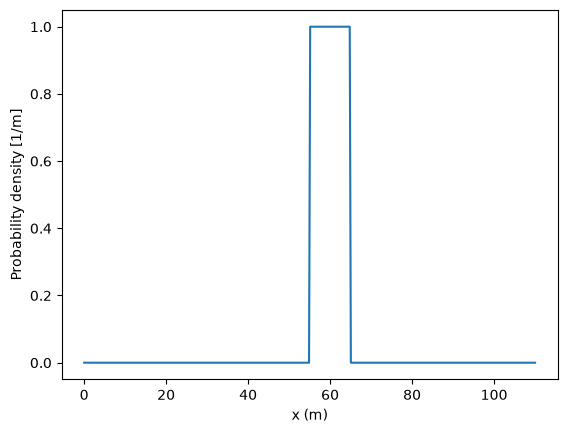

In [19]:
b_height = 1
b_width = 10
b_start = L/2

U = np.heaviside(x-b_start,0.5) # scattering off step potential, everything before the start of step is 0, after 1
U = b_height*(U - np.heaviside(x-(b_start + b_width),0.5)) # scattering off step potential, U- everything before end
#of step is 0, everything after is 1. U-this is means that only the inside of the barrier is 1.

# Uncomment for second potential barrier
# U = U + np.heaviside(x-(b_start + 2*b_width),0.5) 
# U = U - np.heaviside(x-(b_start + 3*b_width),0.5) 
plt.plot(x,U)
plt.ylabel('Probability density [1/m]')
plt.xlabel('x (m)')

## Finite-difference representation of Laplacian and Hamiltonian

In [20]:
Lap = ((-2*np.diag(np.ones(N),0) + np.diag(np.ones(N-1),1) + np.diag(np.ones(N-1),-1)))/(2*dx**2)

H = np.diag(U,0) + Lap #Potential+kinetic

In [21]:
H

array([[-13.15710744,   6.57855372,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  6.57855372, -13.15710744,   6.57855372, ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   6.57855372, -13.15710744, ...,   0.        ,
          0.        ,   0.        ],
       ...,
       [  0.        ,   0.        ,   0.        , ..., -13.15710744,
          6.57855372,   0.        ],
       [  0.        ,   0.        ,   0.        , ...,   6.57855372,
        -13.15710744,   6.57855372],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          6.57855372, -13.15710744]], shape=(400, 400))

## Define initial momentum space wavefunction

In [22]:
# momentum space parameters
k0 = 2
sigma_p = 0.2
dk = 2*np.pi/L
km = N * dk
k = np.linspace(0,km,N)

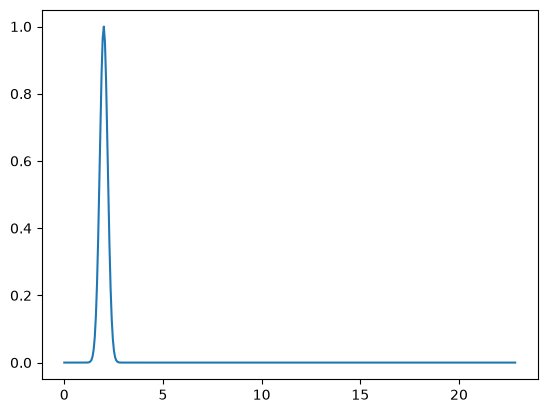

In [23]:
# Gaussian kspace wavefunction phi(k)
phi = np.exp(-(k-k0)**2/(2*sigma_p**2))
plt.plot(k,phi)


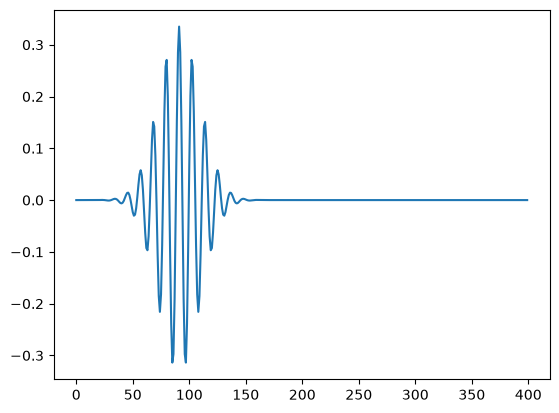

In [24]:
psi_initial = np.fft.ifft(phi)
psi_initial = psi_initial/np.sqrt(np.conj(psi_initial.T)@psi_initial*dx)
psi_initial = np.fft.fftshift(psi_initial)
psi_initial = np.conj(np.roll(psi_initial, int(-30*(N/L))))
plt.plot(np.real(psi_initial))

Text(0.5, 0, 'x (m)')

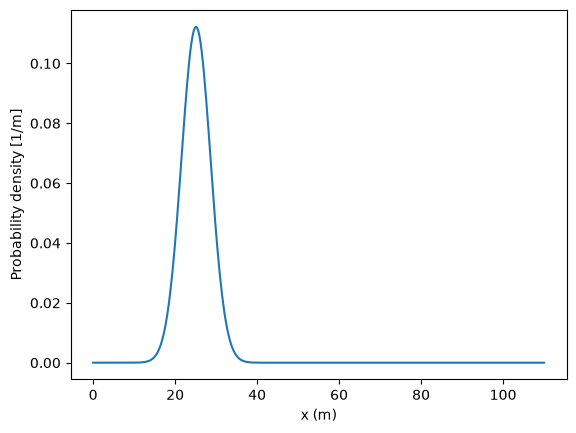

In [25]:
# plt.plot(k,phi)
plt.plot(x,np.real(np.conj(psi_initial.T)* psi_initial))
plt.ylabel('Probability density [1/m]')
plt.xlabel('x (m)')

##  Perform time evolution

In [26]:
tf = 30 
dt=0.5
num = tf/dt
T = np.linspace(0,tf,int(num))
hbar = 1

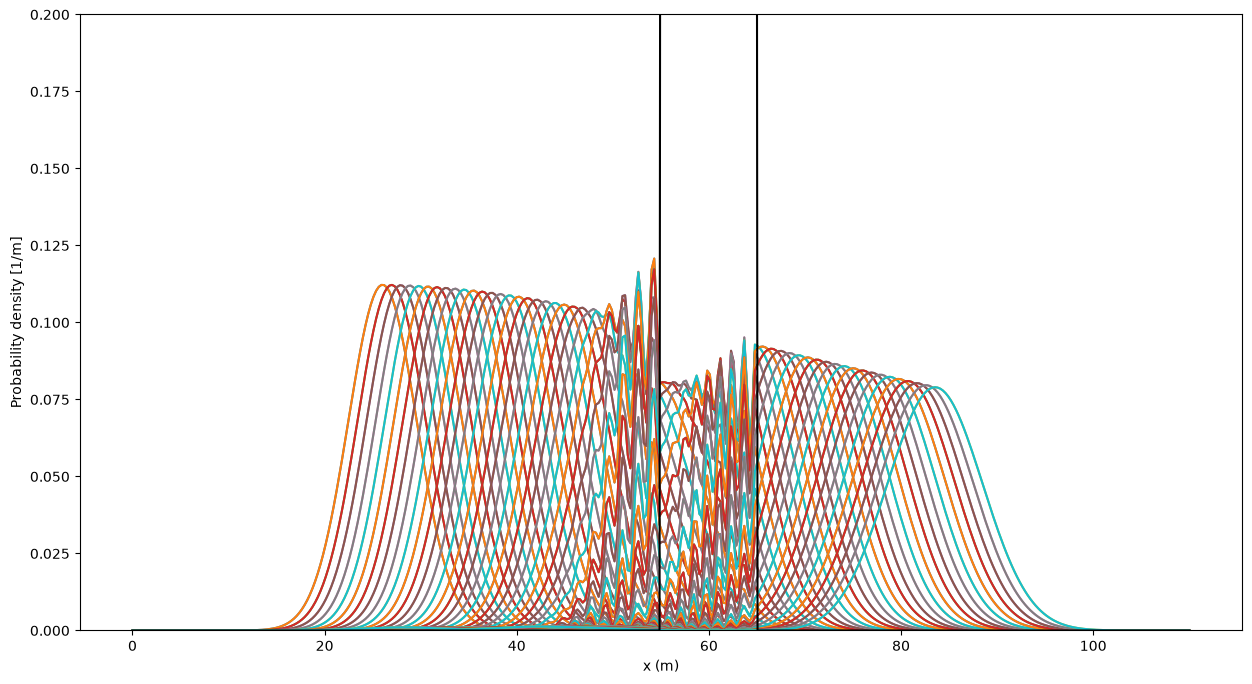

In [27]:
Udt = expm(-1j * H * dt / hbar)
psi = psi_initial
    
plt.figure(figsize=(15, 8))
plt.ylabel('Probability density [1/m]')
plt.xlabel('x (m)')
for time_idx in range(len(T)):
    psi = Udt @ psi
    prob_density = np.abs(np.conj(psi.T)* psi)
#     plt.figure()
    plt.plot(x,prob_density)
    plt.plot(x,prob_density)

plt.ylim(0,0.2)
plt.plot(x,U, color='k')
    

(0.0, 0.2)

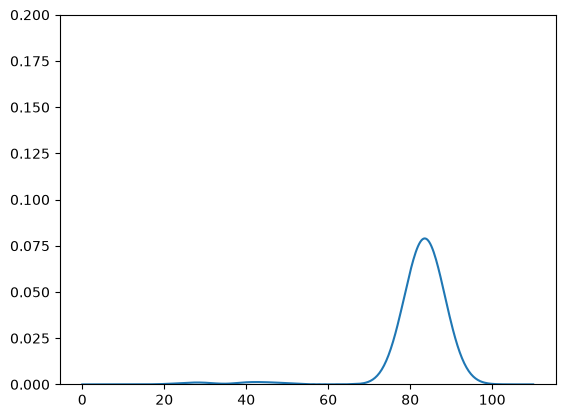

In [28]:
plt.plot(x,prob_density)
plt.ylim(0,0.2)

## Animate the time evolution (looping)

In [29]:
# Animate the wavepacket scattering off the barrier as a looping animation
from matplotlib import animation
from IPython.display import HTML

# Precompute the probability density at every time step (starting from t = 0)
psi = psi_initial
densities = [np.abs(psi)**2]
for time_idx in range(len(T)):
    psi = Udt @ psi
    densities.append(np.abs(psi)**2)

fig, ax = plt.subplots(figsize=(15, 8))
ax.plot(x, U, color='k', label='Potential')
line, = ax.plot(x, densities[0], label='Probability density')
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=14)
ax.set_xlim(0, L)
ax.set_ylim(0, 0.2)
ax.set_xlabel('x (m)')
ax.set_ylabel('Probability density [1/m]')
ax.legend(loc='upper right')

def update(frame):
    line.set_ydata(densities[frame])
    time_text.set_text(f't = {frame*dt:.1f}')
    return line, time_text

anim = animation.FuncAnimation(fig, update, frames=len(densities), interval=60, blit=True)
plt.close(fig)  # prevent a duplicate static figure from being shown

# Interactive player that loops by default
HTML(anim.to_jshtml(default_mode='loop'))